In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

from pathlib import Path

from skimage.transform import resize

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# Paths
DATA_ROOT = Path("../data/raw")
RESULTS_ROOT = Path("../results")

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

IMG_SIZE = 128

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "Pituitary"
]

print("TensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)

TensorFlow: 2.21.0
Image size: 128


In [3]:
mat_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if p.name.lower() != "cvind.mat"
)

print(f"MAT files found: {len(mat_files)}")

MAT files found: 3064


In [4]:
def load_figshare_data(mat_files):
    images = []
    labels = []
    patient_ids = []

    for mat_file in mat_files:

        with h5py.File(mat_file, "r") as f:

            cjdata = f["cjdata"]

            image = np.asarray(
                cjdata["image"],
                dtype=np.float32
            )

            label = int(
                np.asarray(
                    cjdata["label"]
                ).squeeze()
            )

            pid_codes = np.asarray(
                cjdata["PID"]
            ).reshape(-1)

            patient_id = "".join(
                chr(int(code))
                for code in pid_codes
            )

            images.append(image)
            labels.append(label)
            patient_ids.append(patient_id)

    return (
        images,
        np.asarray(labels, dtype=np.int64),
        np.asarray(patient_ids)
    )


images, labels, patient_ids = load_figshare_data(
    mat_files
)

print("Images:", len(images))
print("Labels:", len(labels))
print("Patients:", len(np.unique(patient_ids)))

Images: 3064
Labels: 3064
Patients: 233


In [5]:
X_images = np.empty(
    (len(images), IMG_SIZE, IMG_SIZE),
    dtype=np.float32
)

for i, image in enumerate(images):

    resized = resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        anti_aliasing=True,
        preserve_range=True
    ).astype(np.float32)

    image_min = resized.min()
    image_max = resized.max()

    if image_max > image_min:
        resized = (
            resized - image_min
        ) / (
            image_max - image_min
        )
    else:
        resized = np.zeros_like(resized)

    X_images[i] = resized


y = labels.copy()

print("Input shape:", X_images.shape)
print("Label shape:", y.shape)

Input shape: (3064, 128, 128)
Label shape: (3064,)


In [6]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, test_idx = next(
    gss.split(
        X_images,
        y,
        groups=patient_ids
    )
)


X_train_images = X_images[train_idx]
X_test_images = X_images[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

pid_train = patient_ids[train_idx]
pid_test = patient_ids[test_idx]


print("Training samples:", len(X_train_images))
print("Testing samples :", len(X_test_images))

print(
    "Patient overlap:",
    len(
        set(pid_train) &
        set(pid_test)
    )
)

Training samples: 2452
Testing samples : 612
Patient overlap: 0


In [7]:
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

train_inner_idx, val_idx = next(
    gss_val.split(
        X_train_images,
        y_train,
        groups=pid_train
    )
)


X_train_final = X_train_images[
    train_inner_idx
]

X_val = X_train_images[
    val_idx
]

y_train_final = y_train[
    train_inner_idx
]

y_val = y_train[
    val_idx
]


print("Train:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_images.shape)

Train: (2051, 128, 128)
Validation: (401, 128, 128)
Test: (612, 128, 128)


In [8]:
X_train_flat = X_train_final.reshape(
    X_train_final.shape[0],
    -1
)

X_val_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_flat
)

X_val_scaled = scaler.transform(
    X_val_flat
)

X_test_scaled = scaler.transform(
    X_test_flat
)


print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (2051, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [9]:
y_train_ann = y_train_final - 1
y_val_ann = y_val - 1
y_test_ann = y_test - 1


classes = np.unique(y_train_ann)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ann
)

ann_class_weights = dict(
    zip(
        classes,
        class_weights_array
    )
)

print("Classes:", classes)
print("Class weights:", ann_class_weights)

Classes: [0 1 2]
Class weights: {0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [10]:
ann_v2 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.50),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.40),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v2"
)

ann_v2.summary()

Model: "Brain_Tumor_ANN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [11]:
ann_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [14]:
history_v2 = ann_v2.fit(
    X_train_scaled,
    y_train_ann,

    validation_data=(
        X_val_scaled,
        y_val_ann
    ),

    epochs=100,
    batch_size=32,

    class_weight=ann_class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.8123 - loss: 0.5085
Epoch 1: val_loss did not improve from 0.52425
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.8123 - loss: 0.5085 - val_accuracy: 0.8778 - val_loss: 0.5669 - learning_rate: 5.0000e-04
Epoch 2/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8757 - loss: 0.3859
Epoch 2: val_loss did not improve from 0.52425
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.8757 - loss: 0.3859 - val_accuracy: 0.8903 - val_loss: 0.6225 - learning_rate: 5.0000e-04
Epoch 3/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9044 - loss: 0.3397
Epoch 3: val_loss did not improve from 0.52425
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.9044 - loss: 0.3397 - val_accuracy: 0.8878 - val_loss: 0.7142 - learning_rate: 5.0000e-04
Epoch 4/100
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9194 - loss: 0.2919
Epoch 4: val_loss did not improve from 0.52425
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/s

In [15]:
best_ann_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v2.keras"
)

test_prob_v2 = best_ann_v2.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v2 = np.argmax(
    test_prob_v2,
    axis=1
)


ann_v2_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v2
)

ann_v2_precision = precision_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_recall = recall_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_f1 = f1_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)


print("========== ANN-v2 RESULTS ==========")
print(f"Accuracy        : {ann_v2_accuracy:.4f}")
print(f"Macro Precision : {ann_v2_precision:.4f}")
print(f"Macro Recall    : {ann_v2_recall:.4f}")
print(f"Macro F1        : {ann_v2_f1:.4f}")

========== ANN-v2 RESULTS ==========
Accuracy        : 0.7337
Macro Precision : 0.7079
Macro Recall    : 0.7425
Macro F1        : 0.7028


In [16]:
print(
    classification_report(
        y_test_ann,
        y_pred_v2,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.4510    0.7041    0.5498        98
  Meningioma     0.8830    0.5764    0.6975       288
   Pituitary     0.7897    0.9469    0.8612       226

    accuracy                         0.7337       612
   macro avg     0.7079    0.7425    0.7028       612
weighted avg     0.7793    0.7337    0.7343       612



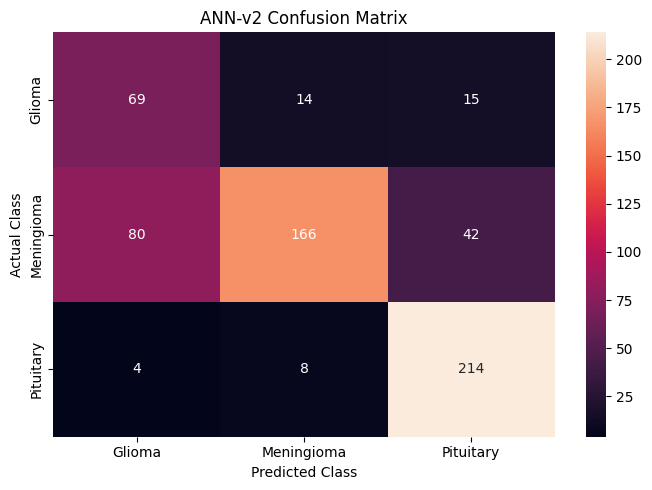

In [17]:
cm_v2 = confusion_matrix(
    y_test_ann,
    y_pred_v2
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v2 Confusion Matrix")

plt.tight_layout()
plt.show()

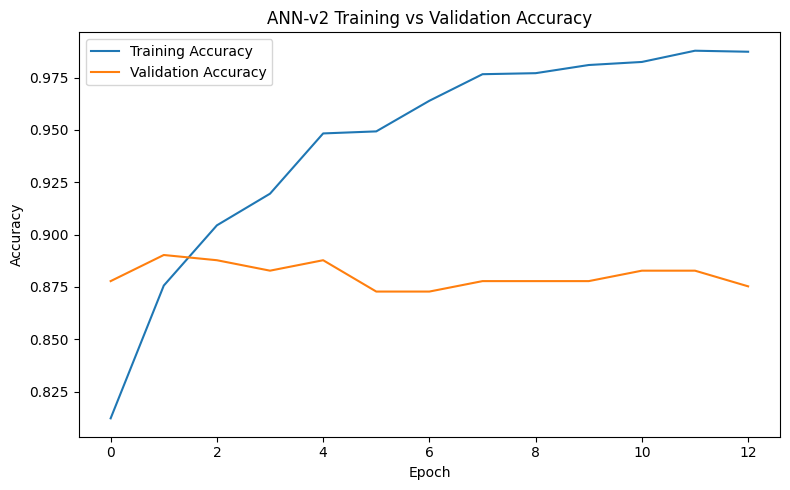

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(
    "ANN-v2 Training vs Validation Accuracy"
)

plt.legend()
plt.tight_layout()
plt.show()

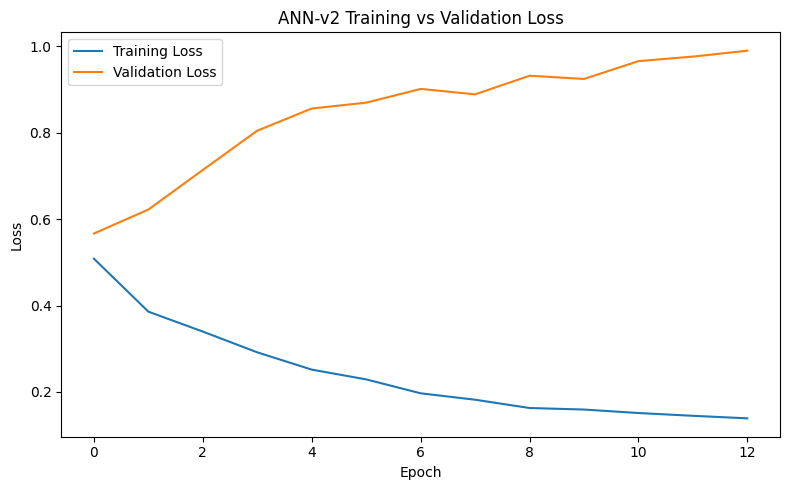

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "ANN-v2 Training vs Validation Loss"
)

plt.legend()
plt.tight_layout()
plt.show()

In [20]:
ann_v3 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.35),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v3"
)

ann_v3.summary()

Model: "Brain_Tumor_ANN_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [21]:
ann_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
early_stopping_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [23]:
history_v3 = ann_v3.fit(
    X_train_scaled,
    y_train_ann,
    validation_data=(
        X_val_scaled,
        y_val_ann
    ),
    epochs=30,
    batch_size=32,
    class_weight=ann_class_weights,
    callbacks=[
        early_stopping_v3,
        reduce_lr_v3,
        checkpoint_v3
    ],
    verbose=1
)

Epoch 1/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.7070 - loss: 0.7452
Epoch 1: val_loss improved from None to 0.46358, saving model to ..\results\best_ann_v3.keras

Epoch 1: finished saving model to ..\results\best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.7070 - loss: 0.7452 - val_accuracy: 0.8354 - val_loss: 0.4636 - learning_rate: 3.0000e-04
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8328 - loss: 0.4616
Epoch 2: val_loss improved from 0.46358 to 0.42729, saving model to ..\results\best_ann_v3.keras

Epoch 2: finished saving model to ..\results\best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.8328 - loss: 0.4616 - val_accuracy: 0.8853 - val_loss: 0.4273 - learning_rate: 3.0000e-04
Epoch 3/30
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.9004 - loss: 0.3122
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 3: val_loss did not improve from 0.42729
65/65 ━━━━━━━━

In [24]:
best_ann_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v3.keras"
)

test_prob_v3 = best_ann_v3.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v3 = np.argmax(
    test_prob_v3,
    axis=1
)

In [25]:
ann_v3_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v3
)

ann_v3_precision = precision_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_recall = recall_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_f1 = f1_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)


print("========== ANN-v3 RESULTS ==========")
print(f"Accuracy        : {ann_v3_accuracy:.4f}")
print(f"Macro Precision : {ann_v3_precision:.4f}")
print(f"Macro Recall    : {ann_v3_recall:.4f}")
print(f"Macro F1        : {ann_v3_f1:.4f}")

========== ANN-v3 RESULTS ==========
Accuracy        : 0.8627
Macro Precision : 0.8248
Macro Recall    : 0.8477
Macro F1        : 0.8337


In [26]:
print(
    classification_report(
        y_test_ann,
        y_pred_v3,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.6522    0.7653    0.7042        98
  Meningioma     0.9189    0.8264    0.8702       288
   Pituitary     0.9034    0.9513    0.9267       226

    accuracy                         0.8627       612
   macro avg     0.8248    0.8477    0.8337       612
weighted avg     0.8705    0.8627    0.8645       612



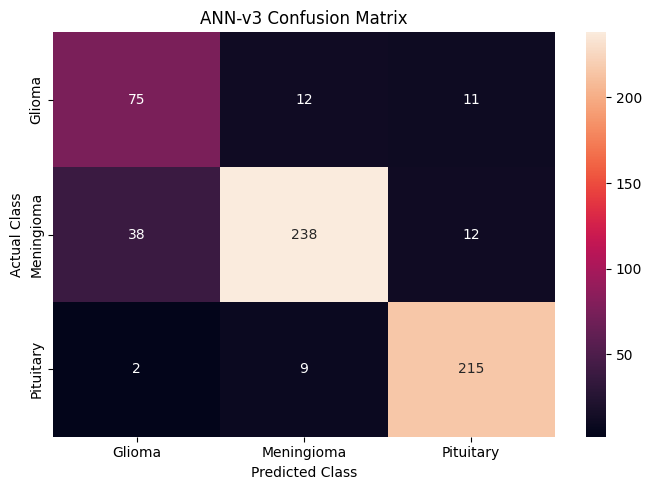

In [27]:
cm_v3 = confusion_matrix(
    y_test_ann,
    y_pred_v3
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v3 Confusion Matrix")

plt.tight_layout()
plt.show()

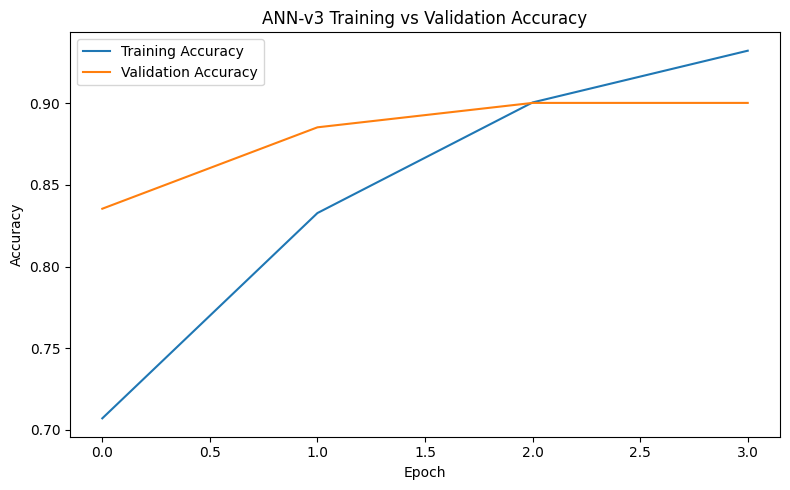

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v3.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v3 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

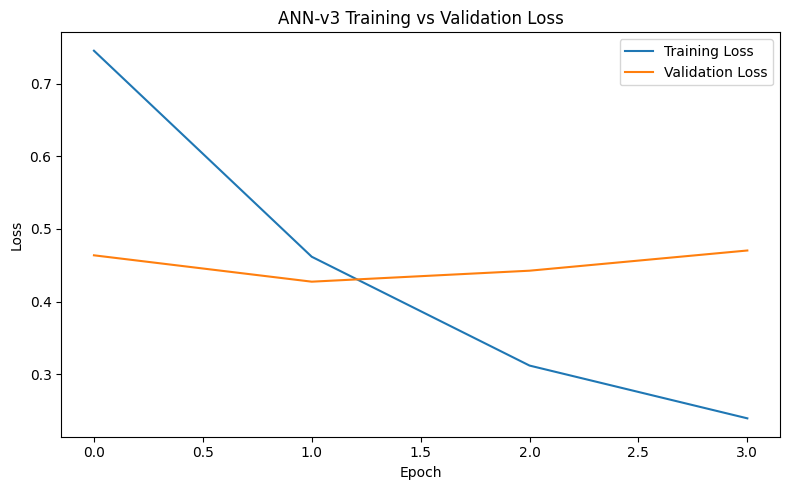

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v3.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v3 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [30]:
ann_comparison = pd.DataFrame({
    "Model": [
        "ANN-v1",
        "ANN-v2",
        "ANN-v3"
    ],

    "Accuracy": [
        0.8252,
        0.8007,
        ann_v3_accuracy
    ],

    "Macro Precision": [
        0.7896,
        0.7653,
        ann_v3_precision
    ],

    "Macro Recall": [
        0.7826,
        0.7986,
        ann_v3_recall
    ],

    "Macro F1": [
        0.7839,
        0.7732,
        ann_v3_f1
    ]
})

ann_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-v1,0.825200,0.789600,0.782600,0.783900
1,ANN-v2,0.800700,0.765300,0.798600,0.773200
2,ANN-v3,0.862745,0.824818,0.847674,0.833717


In [31]:
augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)


X_train_aug = np.empty_like(X_train_final)

for i in range(len(X_train_final)):
    image = X_train_final[i][..., np.newaxis]

    augmented = augmentation(
        image,
        training=True
    ).numpy().squeeze()

    X_train_aug[i] = augmented


# Original + augmented training samples
X_train_combined = np.concatenate(
    [
        X_train_final,
        X_train_aug
    ],
    axis=0
)

y_train_combined = np.concatenate(
    [
        y_train_final,
        y_train_final
    ],
    axis=0
)

print("Original training samples :", len(X_train_final))
print("Augmented training samples:", len(X_train_aug))
print("Combined training samples :", len(X_train_combined))

Original training samples : 2051
Augmented training samples: 2051
Combined training samples : 4102


In [32]:
X_train_v4_flat = X_train_combined.reshape(
    X_train_combined.shape[0],
    -1
)

X_val_v4_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_v4_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler_v4 = StandardScaler()

X_train_v4_scaled = scaler_v4.fit_transform(
    X_train_v4_flat
)

X_val_v4_scaled = scaler_v4.transform(
    X_val_v4_flat
)

X_test_v4_scaled = scaler_v4.transform(
    X_test_v4_flat
)


print("Train:", X_train_v4_scaled.shape)
print("Validation:", X_val_v4_scaled.shape)
print("Test:", X_test_v4_scaled.shape)

Train: (4102, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [33]:
y_train_v4 = y_train_combined - 1
y_val_v4 = y_val - 1
y_test_v4 = y_test - 1


classes_v4 = np.unique(y_train_v4)

class_weights_v4 = compute_class_weight(
    class_weight="balanced",
    classes=classes_v4,
    y=y_train_v4
)

ann_v4_class_weights = dict(
    zip(
        classes_v4,
        class_weights_v4
    )
)

print("Class weights:", ann_v4_class_weights)

Class weights: {0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [34]:
ann_v4 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_v4_scaled.shape[1],)
        ),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            32,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v4"
)

ann_v4.summary()

Model: "Brain_Tumor_ANN_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,108,483 (8.04 MB)

 Trainable params: 2,108,099 (8.04 MB)

 Non-trainable params: 384 (1.50 KB)

In [35]:
ann_v4.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [36]:
early_stopping_v4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v4 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v4 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v4.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [37]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6575 - loss: 0.7784
Epoch 1: val_loss improved from None to 0.43880, saving model to ..\results\best_ann_v4.keras

Epoch 1: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.6575 - loss: 0.7784 - val_accuracy: 0.8354 - val_loss: 0.4388 - learning_rate: 3.0000e-04
Epoch 2/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7472 - loss: 0.5927
Epoch 2: val_loss improved from 0.43880 to 0.37344, saving model to ..\results\best_ann_v4.keras

Epoch 2: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.7472 - loss: 0.5927 - val_accuracy: 0.8753 - val_loss: 0.3734 - learning_rate: 3.0000e-04
Epoch 3/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7932 - loss: 0.4938
Epoch 3: val_loss did not improve from 0.37344
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.7933 - loss: 0.4934 - va

In [38]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9175 - loss: 0.2595
Epoch 1: val_loss did not improve from 0.32123
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.9176 - loss: 0.2593 - val_accuracy: 0.9027 - val_loss: 0.3405 - learning_rate: 7.5000e-05
Epoch 2/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9165 - loss: 0.2440
Epoch 2: val_loss did not improve from 0.32123
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9166 - loss: 0.2438 - val_accuracy: 0.8978 - val_loss: 0.3375 - learning_rate: 7.5000e-05
Epoch 3/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9346 - loss: 0.2098
Epoch 3: val_loss did not improve from 0.32123
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9347 - loss: 0.2096 - val_accuracy: 0.9002 - val_loss: 0.3581 - learning_rate: 7.5000e-05
Epoch 4/40
127/129 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9390 - loss: 0.2042
Epoch 4: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-

In [39]:
best_ann_v4 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v4.keras"
)

test_prob_v4 = best_ann_v4.predict(
    X_test_v4_scaled,
    verbose=0
)

y_pred_v4 = np.argmax(
    test_prob_v4,
    axis=1
)

In [40]:
ann_v4_accuracy = accuracy_score(
    y_test_v4,
    y_pred_v4
)

ann_v4_precision = precision_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_recall = recall_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_f1 = f1_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)


print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8382
Macro Precision : 0.7922
Macro Recall    : 0.8079
Macro F1        : 0.7982


In [41]:
print(
    classification_report(
        y_test_v4,
        y_pred_v4,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.5641    0.6735    0.6140        98
  Meningioma     0.8755    0.8299    0.8520       288
   Pituitary     0.9369    0.9204    0.9286       226

    accuracy                         0.8382       612
   macro avg     0.7922    0.8079    0.7982       612
weighted avg     0.8483    0.8382    0.8422       612



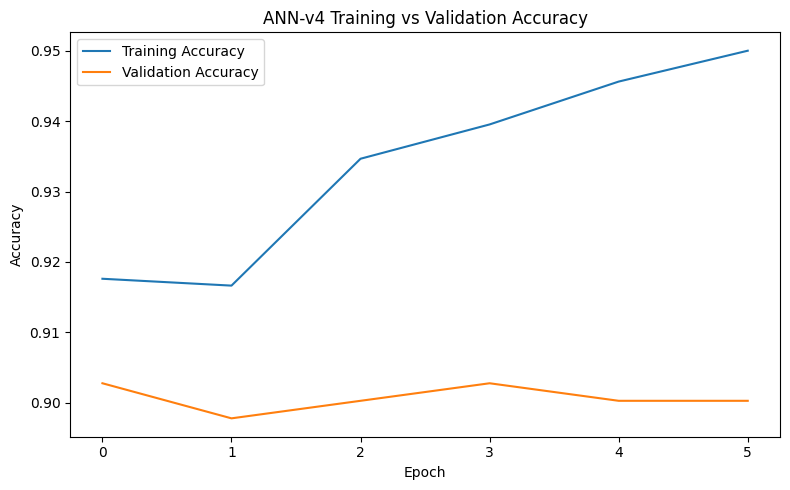

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v4.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v4 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

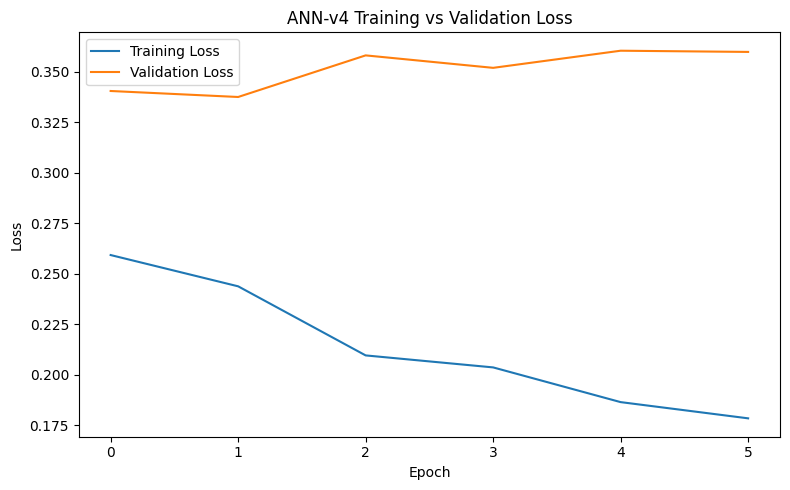

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v4.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v4 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [44]:
print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8382
Macro Precision : 0.7922
Macro Recall    : 0.8079
Macro F1        : 0.7982


In [45]:
## seeing this annv3 is good 
## Now cnn implenataion starts from here


In [46]:
# ============================================================
# ANN HYPERPARAMETER TUNING
# Fixed: Architecture, L2, BatchNorm, Optimizer, Batch Size
# Varied: Dropout Rates and Learning Rate
# ============================================================

ann_experiments = [
    {
        "name": "ANN-Exp1",
        "dropout": [0.20, 0.20, 0.20],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp2",
        "dropout": [0.30, 0.30, 0.30],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp3",
        "dropout": [0.40, 0.40, 0.40],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp4",
        "dropout": [0.20, 0.20, 0.20],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp5",
        "dropout": [0.30, 0.30, 0.30],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp6",
        "dropout": [0.40, 0.40, 0.40],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp7",
        "dropout": [0.35, 0.25, 0.15],
        "learning_rate": 3e-4
    }
]

print("Total experiments:", len(ann_experiments))

Total experiments: 7


In [47]:
def build_ann_experiment(dropout_rates, learning_rate):

    model = keras.Sequential(
        [
            keras.Input(
                shape=(X_train_scaled.shape[1],)
            ),

            layers.Dense(
                256,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[0]),

            layers.Dense(
                128,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[1]),

            layers.Dense(
                64,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[2]),

            layers.Dense(
                3,
                activation="softmax"
            )
        ],
        name="ANN_Hyperparameter_Model"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [48]:
# ============================================================
# TRAIN AND EVALUATE ALL ANN CONFIGURATIONS
# ============================================================

ann_results = []

for exp in ann_experiments:

    print("\n" + "=" * 60)
    print(f"Running {exp['name']}")
    print(f"Dropout      : {exp['dropout']}")
    print(f"Learning Rate: {exp['learning_rate']}")
    print("=" * 60)

    model = build_ann_experiment(
        dropout_rates=exp["dropout"],
        learning_rate=exp["learning_rate"]
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=0
    )

    history = model.fit(
        X_train_scaled,
        y_train_ann,
        validation_data=(
            X_val_scaled,
            y_val_ann
        ),
        epochs=50,
        batch_size=32,
        class_weight=ann_class_weights,
        callbacks=[
            early_stopping,
            reduce_lr
        ],
        verbose=0
    )

    test_prob = model.predict(
        X_test_scaled,
        verbose=0
    )

    y_pred = np.argmax(
        test_prob,
        axis=1
    )

    accuracy = accuracy_score(
        y_test_ann,
        y_pred
    )

    precision = precision_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    ann_results.append(
        {
            "Model": exp["name"],
            "Dropout": str(exp["dropout"]),
            "Learning Rate": exp["learning_rate"],
            "Best Val Accuracy": max(
                history.history["val_accuracy"]
            ),
            "Best Val Loss": min(
                history.history["val_loss"]
            ),
            "Test Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1
        }
    )

    print(f"Test Accuracy : {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall   : {recall:.4f}")
    print(f"Macro F1       : {f1:.4f}")


Running ANN-Exp1
Dropout      : [0.2, 0.2, 0.2]
Learning Rate: 0.001
Test Accuracy : 0.8415
Macro Precision: 0.8036
Macro Recall   : 0.8134
Macro F1       : 0.8077

Running ANN-Exp2
Dropout      : [0.3, 0.3, 0.3]
Learning Rate: 0.001
Test Accuracy : 0.8350
Macro Precision: 0.7944
Macro Recall   : 0.8165
Macro F1       : 0.8020

Running ANN-Exp3
Dropout      : [0.4, 0.4, 0.4]
Learning Rate: 0.001
Test Accuracy : 0.8023
Macro Precision: 0.7670
Macro Recall   : 0.7936
Macro F1       : 0.7712

Running ANN-Exp4
Dropout      : [0.2, 0.2, 0.2]
Learning Rate: 0.0005
Test Accuracy : 0.8333
Macro Precision: 0.7928
Macro Recall   : 0.8112
Macro F1       : 0.8002

Running ANN-Exp5
Dropout      : [0.3, 0.3, 0.3]
Learning Rate: 0.0005
Test Accuracy : 0.8480
Macro Precision: 0.8099
Macro Recall   : 0.8363
Macro F1       : 0.8196

Running ANN-Exp6
Dropout      : [0.4, 0.4, 0.4]
Learning Rate: 0.0005
Test Accuracy : 0.8219
Macro Precision: 0.7844
Macro Recall   : 0.7985
Macro F1       : 0.7886

Runnin

In [49]:
# ============================================================
# ANN EXPERIMENT COMPARISON
# ============================================================

ann_results_df = pd.DataFrame(
    ann_results
)

ann_results_df = ann_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

ann_results_df

,Model,Dropout,Learning Rate,Best Val Accuracy,Best Val Loss,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-Exp7,"[0.35, 0.25, 0.15]",0.0003,0.895262,0.560973,0.872549,0.836187,0.865860,0.846646
1,ANN-Exp5,"[0.3, 0.3, 0.3]",0.0005,0.895262,0.418246,0.848039,0.809852,0.836305,0.819588
2,ANN-Exp1,"[0.2, 0.2, 0.2]",0.0010,0.892768,0.430677,0.841503,0.803564,0.813406,0.807744
3,ANN-Exp2,"[0.3, 0.3, 0.3]",0.0010,0.910224,0.457285,0.834967,0.794364,0.816461,0.802002
4,ANN-Exp4,"[0.2, 0.2, 0.2]",0.0005,0.882793,0.486204,0.833333,0.792767,0.811154,0.800206
5,ANN-Exp6,"[0.4, 0.4, 0.4]",0.0005,0.900249,0.387648,0.821895,0.784382,0.798543,0.788598
6,ANN-Exp3,"[0.4, 0.4, 0.4]",0.0010,0.890274,0.355181,0.802288,0.767048,0.793630,0.771243


In [50]:
best_ann = ann_results_df.iloc[0]

print("=" * 50)
print("BEST ANN CONFIGURATION")
print("=" * 50)

print(f"Model           : {best_ann['Model']}")
print(f"Dropout         : {best_ann['Dropout']}")
print(f"Learning Rate   : {best_ann['Learning Rate']}")
print(f"Test Accuracy   : {best_ann['Test Accuracy']:.4f}")
print(f"Macro Precision : {best_ann['Macro Precision']:.4f}")
print(f"Macro Recall    : {best_ann['Macro Recall']:.4f}")
print(f"Macro F1        : {best_ann['Macro F1']:.4f}")

BEST ANN CONFIGURATION
Model           : ANN-Exp7
Dropout         : [0.35, 0.25, 0.15]
Learning Rate   : 0.0003
Test Accuracy   : 0.8725
Macro Precision : 0.8362
Macro Recall    : 0.8659
Macro F1        : 0.8466


In [51]:
X_train_cnn = X_train_final[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test_images[..., np.newaxis]

y_train_cnn = y_train_final - 1
y_val_cnn = y_val - 1
y_test_cnn = y_test - 1

print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Test:", X_test_cnn.shape)

Training: (2051, 128, 128, 1)
Validation: (401, 128, 128, 1)
Test: (612, 128, 128, 1)


In [52]:
from sklearn.utils.class_weight import compute_class_weight

classes_cnn = np.unique(y_train_cnn)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_cnn,
    y=y_train_cnn
)

cnn_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes_cnn,
        class_weights
    )
}

print("CNN Class Weights")
print("-" * 30)

for class_id, weight in cnn_class_weights.items():
    print(f"Class {class_id}: {weight:.4f}")

CNN Class Weights
------------------------------
Class 0: 1.2341
Class 1: 0.6878
Class 2: 1.3592


In [53]:
# ============================================================
# MRI DATA AUGMENTATION
# ============================================================

cnn_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        ),
        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)

In [54]:
# ============================================================
# CNN-V1 ARCHITECTURE
# ============================================================

cnn_model = keras.Sequential(
    [
        keras.Input(
            shape=(128, 128, 1)
        ),

        cnn_augmentation,

        # -------------------------
        # Convolution Block 1
        # -------------------------
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.20),

        # -------------------------
        # Convolution Block 2
        # -------------------------
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.25),

        # -------------------------
        # Convolution Block 3
        # -------------------------
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.30),

        # -------------------------
        # Feature Aggregation
        # -------------------------
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Dropout(0.40),

        # -------------------------
        # Output
        # -------------------------
        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN"
)

cnn_model.summary()

Model: "Brain_Tumor_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MRI_Augmentation (Sequential)   │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_32 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_33 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_34 (Activation)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 305,635 (1.17 MB)

 Trainable params: 304,483 (1.16 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [55]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [56]:
# ============================================================
# CNN TRAINING CALLBACKS
# ============================================================

early_stopping_cnn = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_model.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [57]:
# ============================================================
# CNN TRAINING
# ============================================================

history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn,
        reduce_lr_cnn,
        checkpoint_cnn
    ],
    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5680 - loss: 0.9662
Epoch 1: val_loss improved from None to 1.35750, saving model to ..\results\best_cnn_model.keras

Epoch 1: finished saving model to ..\results\best_cnn_model.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.5680 - loss: 0.9662 - val_accuracy: 0.3591 - val_loss: 1.3575 - learning_rate: 3.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6767 - loss: 0.7350
Epoch 2: val_loss did not improve from 1.35750
65/65 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.6767 - loss: 0.7350 - val_accuracy: 0.3591 - val_loss: 2.2285 - learning_rate: 3.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7304 - loss: 0.6579
Epoch 3: val_loss did not improve from 1.35750
65/65 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.7304 - loss: 0.6579 - val_accuracy: 0.3591 - val_loss: 3.0553 - learning_rate: 3.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7

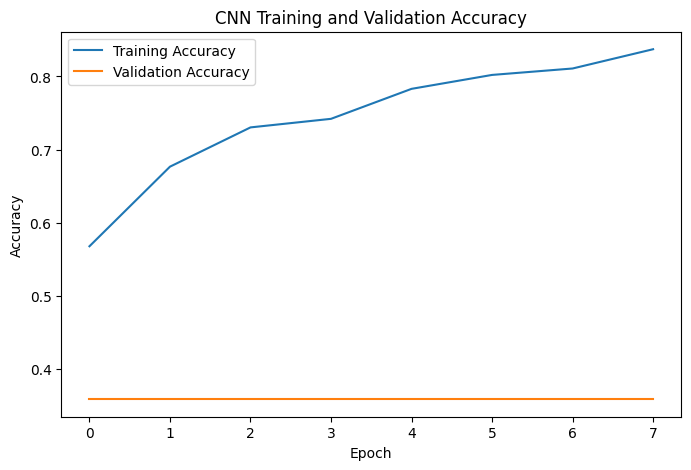

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

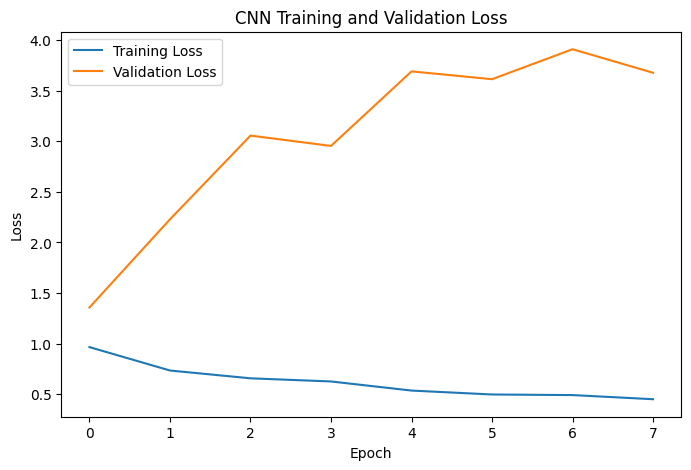

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.show()

In [60]:
# ============================================================
# CNN TEST EVALUATION
# ============================================================

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

test_prob_cnn = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn = np.argmax(
    test_prob_cnn,
    axis=1
)

In [61]:
cnn_accuracy = accuracy_score(
    y_test_cnn,
    y_pred_cnn
)

cnn_precision = precision_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_recall = recall_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_f1 = f1_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

print("========== CNN RESULTS ==========")

print(f"Accuracy        : {cnn_accuracy:.4f}")
print(f"Macro Precision : {cnn_precision:.4f}")
print(f"Macro Recall    : {cnn_recall:.4f}")
print(f"Macro F1        : {cnn_f1:.4f}")

========== CNN RESULTS ==========
Accuracy        : 0.4706
Macro Precision : 0.1569
Macro Recall    : 0.3333
Macro F1        : 0.2133


In [62]:
print(
    classification_report(
        y_test_cnn,
        y_pred_cnn,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000        98
           1     0.4706    1.0000    0.6400       288
           2     0.0000    0.0000    0.0000       226

    accuracy                         0.4706       612
   macro avg     0.1569    0.3333    0.2133       612
weighted avg     0.2215    0.4706    0.3012       612



c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [63]:
print("Train:", np.unique(y_train_cnn, return_counts=True))
print("Val  :", np.unique(y_val_cnn, return_counts=True))
print("Test :", np.unique(y_test_cnn, return_counts=True))

Train: (array([0, 1, 2], dtype=int64), array([554, 994, 503], dtype=int64))
Val  : (array([0, 1, 2], dtype=int64), array([ 56, 144, 201], dtype=int64))
Test : (array([0, 1, 2], dtype=int64), array([ 98, 288, 226], dtype=int64))


In [64]:
print(cnn_class_weights)

{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [65]:
print(
    "Predictions:",
    np.unique(y_pred_cnn, return_counts=True)
)

Predictions: (array([1], dtype=int64), array([612], dtype=int64))


In [66]:
print("Training accuracy:")
print(history_cnn.history["accuracy"])

print("\nValidation accuracy:")
print(history_cnn.history["val_accuracy"])

print("\nTraining loss:")
print(history_cnn.history["loss"])

print("\nValidation loss:")
print(history_cnn.history["val_loss"])

Training accuracy:
[0.5680155754089355, 0.6767430305480957, 0.7303754091262817, 0.7420770525932312, 0.7830326557159424, 0.8020477890968323, 0.8108239769935608, 0.8371526002883911]

Validation accuracy:
[0.3591022491455078, 0.3591022491455078, 0.3591022491455078, 0.3591022491455078, 0.3591022491455078, 0.3591022491455078, 0.3591022491455078, 0.3591022491455078]

Training loss:
[0.966222882270813, 0.735015869140625, 0.657889187335968, 0.6268026828765869, 0.5369078516960144, 0.4981825053691864, 0.49228835105895996, 0.45142313838005066]

Validation loss:
[1.35750150680542, 2.228472948074341, 3.055306911468506, 2.9532296657562256, 3.6894617080688477, 3.612211227416992, 3.908393144607544, 3.6757009029388428]


In [67]:
print("Final learning rate:")

print(
    float(
        cnn_model.optimizer.learning_rate.numpy()
    )
)

Final learning rate:
7.500000356230885e-05


In [68]:
print("First 10 prediction probabilities:")

print(
    test_prob_cnn[:10]
)

First 10 prediction probabilities:
[[0.2542518  0.5884719  0.1572763 ]
 [0.2542883  0.5884594  0.1572523 ]
 [0.25376403 0.58883286 0.15740307]
 [0.25420943 0.58850104 0.15728956]
 [0.25434673 0.58841485 0.15723845]
 [0.25430435 0.588496   0.1571997 ]
 [0.25425106 0.58852017 0.15722877]
 [0.2557258  0.58749896 0.15677525]
 [0.25548428 0.5876128  0.15690283]
 [0.2537632  0.58872706 0.15750971]]


In [69]:
print("Current model evaluation:")
cnn_current_prob = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_current_pred = np.argmax(cnn_current_prob, axis=1)

print(
    np.unique(
        cnn_current_pred,
        return_counts=True
    )
)

print("\nCheckpoint model evaluation:")

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

cnn_best_prob = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

cnn_best_pred = np.argmax(cnn_best_prob, axis=1)

print(
    np.unique(
        cnn_best_pred,
        return_counts=True
    )
)

Current model evaluation:
(array([1], dtype=int64), array([612], dtype=int64))

Checkpoint model evaluation:
(array([1], dtype=int64), array([612], dtype=int64))


In [70]:
print("Current model evaluation:")
cnn_current_prob = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_current_pred = np.argmax(cnn_current_prob, axis=1)

print(
    np.unique(
        cnn_current_pred,
        return_counts=True
    )
)

print("\nCheckpoint model evaluation:")

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

cnn_best_prob = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

cnn_best_pred = np.argmax(cnn_best_prob, axis=1)

print(
    np.unique(
        cnn_best_pred,
        return_counts=True
    )
)

Current model evaluation:
(array([1], dtype=int64), array([612], dtype=int64))

Checkpoint model evaluation:
(array([1], dtype=int64), array([612], dtype=int64))


In [71]:
cnn_v2 = keras.Sequential(
    [
        keras.Input(shape=(128, 128, 1)),

        cnn_augmentation,

        # Block 1
        layers.Conv2D(
            32, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.15),

        # Block 2
        layers.Conv2D(
            64, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(
            64, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.20),

        # Block 3
        layers.Conv2D(
            128, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.25),

        # Feature aggregation
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN_v2"
)

In [72]:
cnn_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [73]:
early_stopping_cnn_v2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn_v2 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn_v2 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [74]:
history_cnn_v2 = cnn_v2.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn_v2,
        reduce_lr_cnn_v2,
        checkpoint_cnn_v2
    ],
    verbose=1
)


Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 744ms/step - accuracy: 0.5963 - loss: 0.9251
Epoch 1: val_loss improved from None to 1.30394, saving model to ..\results\best_cnn_v2.keras

Epoch 1: finished saving model to ..\results\best_cnn_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 56s 781ms/step - accuracy: 0.5963 - loss: 0.9251 - val_accuracy: 0.3591 - val_loss: 1.3039 - learning_rate: 1.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 763ms/step - accuracy: 0.6285 - loss: 0.8160
Epoch 2: val_loss did not improve from 1.30394
65/65 ━━━━━━━━━━━━━━━━━━━━ 51s 791ms/step - accuracy: 0.6285 - loss: 0.8160 - val_accuracy: 0.3591 - val_loss: 1.5782 - learning_rate: 1.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 766ms/step - accuracy: 0.6529 - loss: 0.7528
Epoch 3: val_loss did not improve from 1.30394
65/65 ━━━━━━━━━━━━━━━━━━━━ 52s 798ms/step - accuracy: 0.6529 - loss: 0.7528 - val_accuracy: 0.3591 - val_loss: 1.8109 - learning_rate: 1.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 804ms/step 

In [75]:
best_cnn_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_v2.keras"
)

test_prob_cnn_v2 = best_cnn_v2.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn_v2 = np.argmax(
    test_prob_cnn_v2,
    axis=1
)

print(
    np.unique(
        y_pred_cnn_v2,
        return_counts=True
    )
)

(array([0, 1, 2], dtype=int64), array([ 21, 321, 270], dtype=int64))


In [76]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("CNN-v2 Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        y_pred_cnn_v2,
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2"
        ],
        digits=4
    )
)

print("Accuracy:",
      accuracy_score(y_test_cnn, y_pred_cnn_v2))

print("Macro Precision:",
      precision_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("Macro Recall:",
      recall_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("Macro F1:",
      f1_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_cnn,
        y_pred_cnn_v2
    )
)

CNN-v2 Classification Report:

              precision    recall  f1-score   support

     Class 0     0.2857    0.0612    0.1008        98
     Class 1     0.7726    0.8611    0.8144       288
     Class 2     0.8111    0.9690    0.8831       226

    accuracy                         0.7729       612
   macro avg     0.6231    0.6305    0.5995       612
weighted avg     0.7088    0.7729    0.7255       612

Accuracy: 0.7728758169934641
Macro Precision: 0.6231370222024427
Macro Recall: 0.6304540498598653
Macro F1: 0.5994515900538933

Confusion Matrix:
[[  6  67  25]
 [ 14 248  26]
 [  1   6 219]]


In [77]:
print("Original labels:", np.unique(labels))

for original_label, class_name in zip(
    [1, 2, 3],
    ["Glioma", "Meningioma", "Pituitary"]
):
    print(original_label, "->", class_name)

Original labels: [1 2 3]
1 -> Glioma
2 -> Meningioma
3 -> Pituitary


In [78]:
print("CNN labels:")
print("0 -> original label 1")
print("1 -> original label 2")
print("2 -> original label 3")

CNN labels:
0 -> original label 1
1 -> original label 2
2 -> original label 3


In [79]:
cnn_v3 = keras.Sequential(
    [
        keras.Input(shape=(128, 128, 1)),

        cnn_augmentation,

        # Block 1
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.15),

        # Block 2
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.20),

        # Block 3
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        # Block 4
        layers.Conv2D(
            256,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        # Feature aggregation
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        # Output
        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN_v3"
)

In [80]:
cnn_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [81]:
early_stopping_cnn_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [82]:
history_cnn_v3 = cnn_v3.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn_v3,
        reduce_lr_cnn_v3,
        checkpoint_cnn_v3
    ],
    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5802 - loss: 0.9221
Epoch 1: val_loss improved from None to 2.15699, saving model to ..\results\best_cnn_v3.keras

Epoch 1: finished saving model to ..\results\best_cnn_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.5802 - loss: 0.9221 - val_accuracy: 0.3591 - val_loss: 2.1570 - learning_rate: 1.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6431 - loss: 0.7612
Epoch 2: val_loss did not improve from 2.15699
65/65 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.6431 - loss: 0.7612 - val_accuracy: 0.3591 - val_loss: 3.6403 - learning_rate: 1.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6782 - loss: 0.6849
Epoch 3: val_loss did not improve from 2.15699
65/65 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.6782 - loss: 0.6849 - val_accuracy: 0.3591 - val_loss: 4.6690 - learning_rate: 1.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6914 

In [83]:
best_cnn_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_v3.keras"
)

test_prob_cnn_v3 = best_cnn_v3.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn_v3 = np.argmax(
    test_prob_cnn_v3,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        y_pred_cnn_v3,
        return_counts=True
    )
)

Prediction distribution: (array([1], dtype=int64), array([612], dtype=int64))


In [84]:
print("Train pixel statistics:")
print("Min:", X_train_cnn.min())
print("Max:", X_train_cnn.max())
print("Mean:", X_train_cnn.mean())
print("Std:", X_train_cnn.std())

print("\nValidation pixel statistics:")
print("Min:", X_val_cnn.min())
print("Max:", X_val_cnn.max())
print("Mean:", X_val_cnn.mean())
print("Std:", X_val_cnn.std())

print("\nTest pixel statistics:")
print("Min:", X_test_cnn.min())
print("Max:", X_test_cnn.max())
print("Mean:", X_test_cnn.mean())
print("Std:", X_test_cnn.std())

Train pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.18868329
Std: 0.19725342

Validation pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.19971013
Std: 0.19670263

Test pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.19466703
Std: 0.19543687


In [85]:
print("Individual image statistics:")

for i in range(5):
    img = X_train_cnn[i]

    print(
        f"Image {i}: "
        f"min={img.min():.4f}, "
        f"max={img.max():.4f}, "
        f"mean={img.mean():.4f}, "
        f"std={img.std():.4f}"
    )

Individual image statistics:
Image 0: min=0.0000, max=1.0000, mean=0.2571, std=0.1961
Image 1: min=0.0000, max=1.0000, mean=0.2553, std=0.1936
Image 2: min=0.0000, max=1.0000, mean=0.2609, std=0.1948
Image 3: min=0.0000, max=1.0000, mean=0.2214, std=0.1638
Image 4: min=0.0000, max=1.0000, mean=0.2284, std=0.1677


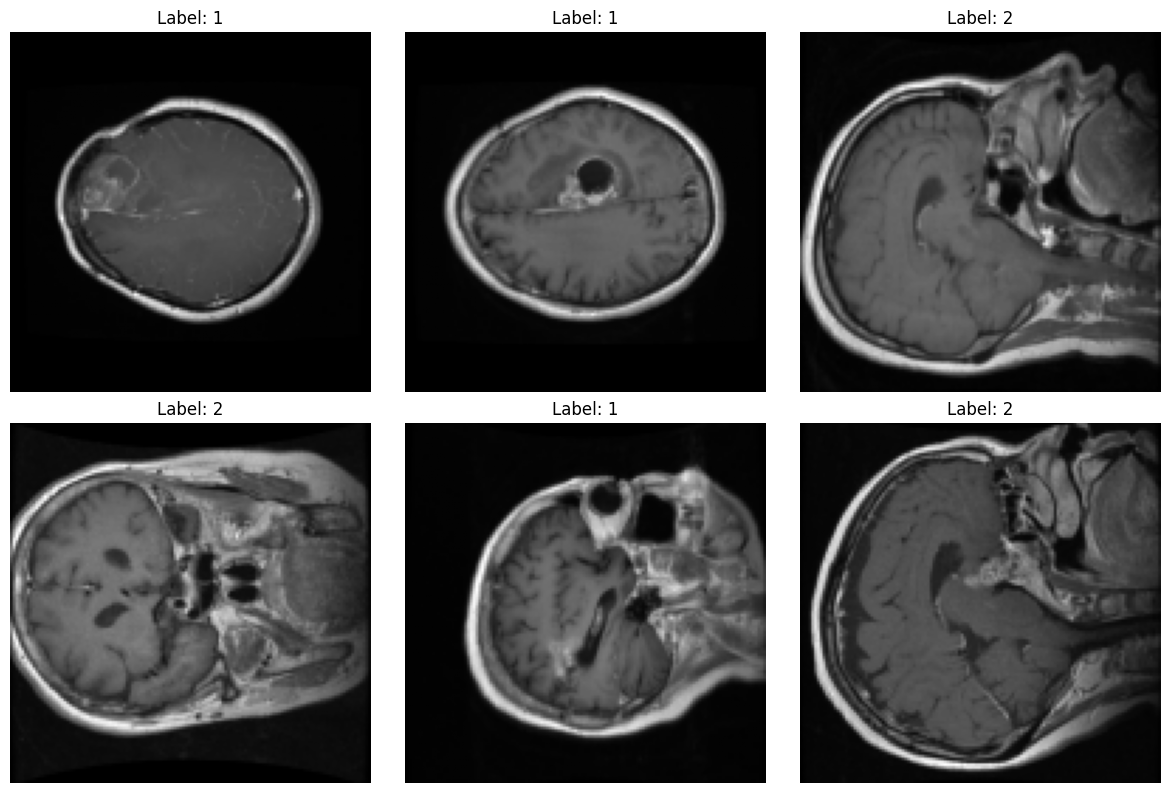

In [86]:
import matplotlib.pyplot as plt
import numpy as np

indices = np.random.choice(
    len(X_train_cnn),
    size=6,
    replace=False
)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 3, i + 1)
    plt.imshow(
        X_train_cnn[idx].squeeze(),
        cmap="gray"
    )
    plt.title(f"Label: {y_train_cnn[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

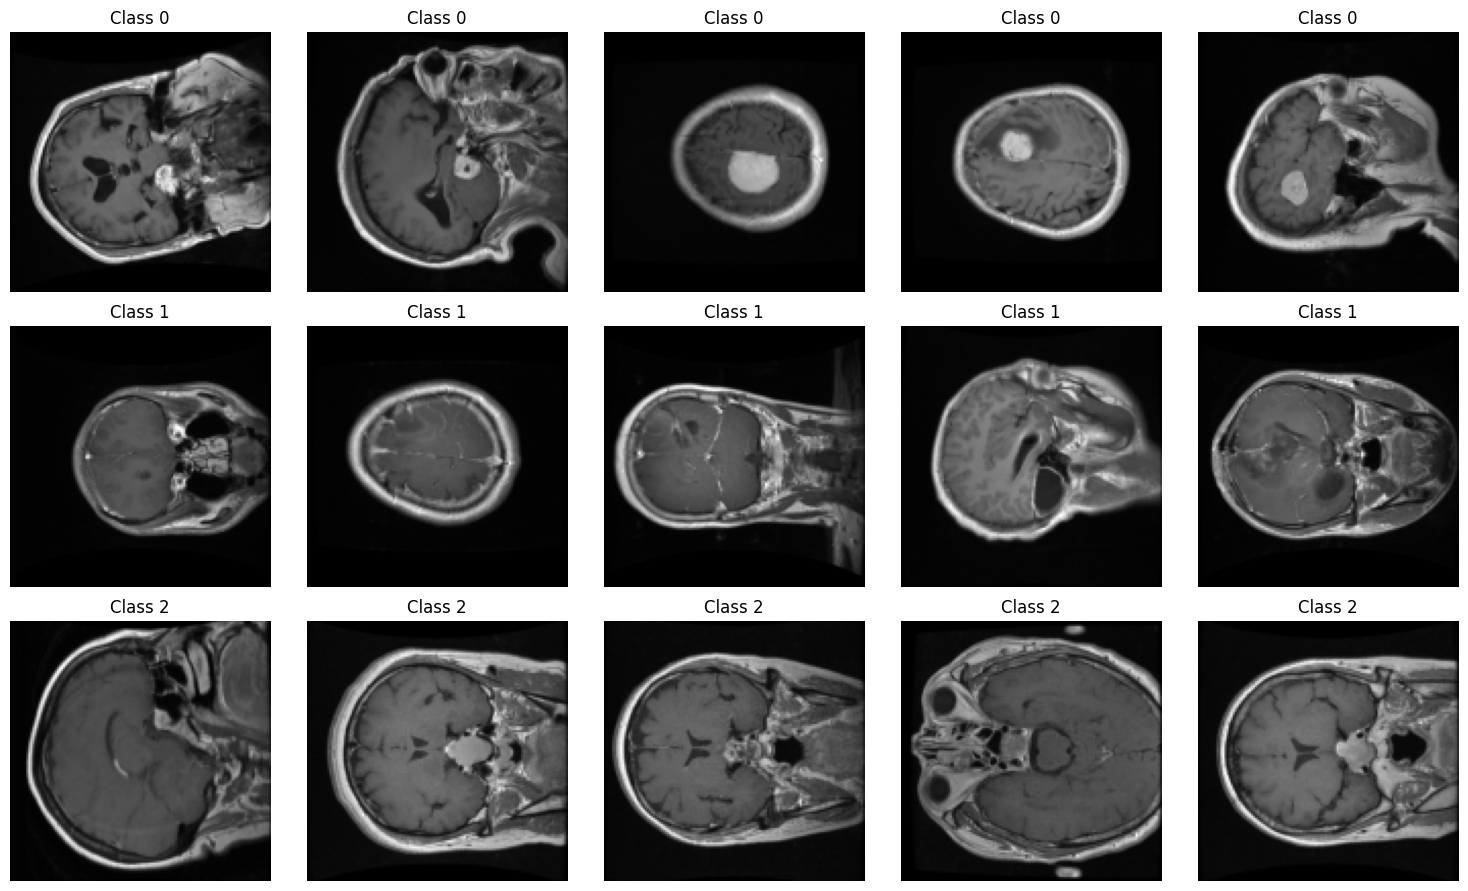

In [87]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for class_id in [0, 1, 2]:

    class_indices = np.where(
        y_train_cnn == class_id
    )[0]

    selected = np.random.choice(
        class_indices,
        size=5,
        replace=False
    )

    for j, idx in enumerate(selected):

        axes[class_id, j].imshow(
            X_train_cnn[idx].squeeze(),
            cmap="gray"
        )

        axes[class_id, j].set_title(
            f"Class {class_id}"
        )

        axes[class_id, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Transfer Learning CNN
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Convert grayscale MRI to 3-channel RGB-like format
X_train_tl = np.repeat(
    X_train_cnn,
    3,
    axis=-1
)

X_val_tl = np.repeat(
    X_val_cnn,
    3,
    axis=-1
)

X_test_tl = np.repeat(
    X_test_cnn,
    3,
    axis=-1
)

print("Train:", X_train_tl.shape)
print("Validation:", X_val_tl.shape)
print("Test:", X_test_tl.shape)

Train: (2051, 128, 128, 3)
Validation: (401, 128, 128, 3)
Test: (612, 128, 128, 3)


In [89]:
tl_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.04,
            width_factor=0.04,
            fill_mode="nearest"
        ),
        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_TL_Augmentation"
)

In [90]:
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

base_model.trainable = False

print("Total backbone layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 36s 2us/step
Total backbone layers: 238


In [91]:
inputs = keras.Input(
    shape=(128, 128, 3)
)

x = tl_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

cnn_tl = keras.Model(
    inputs,
    outputs,
    name="Brain_Tumor_EfficientNetB0"
)

cnn_tl.summary()

Model: "Brain_Tumor_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MRI_TL_Augmentation             │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_50 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,438 (16.08 MB)

 Trainable params: 164,611 (643.01 KB)

 Non-trainable params: 4,049,827 (15.45 MB)

In [92]:
cnn_tl.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [93]:
early_stopping_tl = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_tl = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_tl = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_transfer_learning.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [94]:
history_tl = cnn_tl.fit(
    X_train_tl,
    y_train_cnn,

    validation_data=(
        X_val_tl,
        y_val_cnn
    ),

    epochs=25,
    batch_size=32,

    class_weight=cnn_class_weights,

    callbacks=[
        early_stopping_tl,
        reduce_lr_tl,
        checkpoint_tl
    ],

    verbose=1
)

Epoch 1/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.3286 - loss: 1.2070
Epoch 1: val_loss improved from None to 1.02601, saving model to ..\results\best_cnn_transfer_learning.keras

Epoch 1: finished saving model to ..\results\best_cnn_transfer_learning.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 47s 395ms/step - accuracy: 0.3286 - loss: 1.2070 - val_accuracy: 0.5012 - val_loss: 1.0260 - learning_rate: 1.0000e-04
Epoch 2/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.3203 - loss: 1.1815
Epoch 2: val_loss did not improve from 1.02601
65/65 ━━━━━━━━━━━━━━━━━━━━ 19s 292ms/step - accuracy: 0.3203 - loss: 1.1815 - val_accuracy: 0.5012 - val_loss: 1.0436 - learning_rate: 1.0000e-04
Epoch 3/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.3671 - loss: 1.1457
Epoch 3: val_loss did not improve from 1.02601
65/65 ━━━━━━━━━━━━━━━━━━━━ 19s 293ms/step - accuracy: 0.3671 - loss: 1.1457 - val_accuracy: 0.3591 - val_loss: 1.1010 - learning_rate: 1.0000e-04
Epoch 4/25
65/65 ━━━━━

In [95]:
best_cnn_tl = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_transfer_learning.keras"
)

test_prob_tl = best_cnn_tl.predict(
    X_test_tl,
    verbose=0
)

y_pred_tl = np.argmax(
    test_prob_tl,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        y_pred_tl,
        return_counts=True
    )
)

Prediction distribution: (array([2], dtype=int64), array([612], dtype=int64))
